# Resultados da Sprint 1

Classificação de perfis associados à hiperglicemia crônica clinicamente significativa (HbA1c ≥ 6,5%) na Subamostra Laboratorial da PNS 2013.

Este notebook só orquestra. A lógica fica em `src/`. É o texto da arguição e a fonte das figuras do LaTeX: se alguma etapa não puder ser chamada de `src/`, o problema está em `src/`, não aqui.

Para reproduzir pela linha de comando: `python -m src.experimento --figuras` (alvo `make figuras`). As tabelas e figuras abaixo são os mesmos artefatos.

In [ ]:
import sys
from pathlib import Path

from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import benchmark as bm
from src import colinearidade as col
from src import data as dt
from src import evaluate as ev
from src import experimento as exp

## 1. Amostra

Do CSV bruto ao conjunto analítico. As exclusões são as duas da §3 da spec. As contagens vêm de onde o corte acontece; nada é recontado aqui.

As **duas prevalências** medem coisas diferentes. A amostral é o desbalanceamento que `class_weight='balanced'` corrige e o contexto de todas as métricas daqui para frente. A ponderada por `peso_lab` estima parâmetro populacional e só aparece nesta seção: o peso amostral entra na EDA descritiva e não entra no treino de nenhum estimador (R9).

In [ ]:
analitico = dt.carregar_analitico()
dt.resumo_amostra(analitico)

,item,n,proporcao
0,Linhas no CSV bruto,8952,NaN
1,Duplicadas removidas,0,NaN
2,Excluídas — HbA1c ausente (R3),-411,NaN
3,Excluídas — bloco de medição integralmente aus...,-90,NaN
4,Amostra analítica,8451,NaN
5,"Positivos (HbA1c ≥ 6,5%)",593,0.070169
6,Prevalência ponderada por peso_lab (R9 — descr...,<NA>,0.063575


O split é a primeira operação entre linhas do projeto: nada que olhe para mais de um registro acontece antes dele (R1). 80/20 estratificado pelo alvo, `random_state=42`.

In [ ]:
particao = exp.preparar_particao()

print(f"Treino {len(particao.X_tr):>5} registros - prevalencia {particao.y_tr.mean():.4f}")
print(f"Teste  {len(particao.X_te):>5} registros - prevalencia {particao.y_te.mean():.4f}")

Treino  6760 registros - prevalencia 0.0701
Teste   1691 registros - prevalencia 0.0704


Os ausentes remanescentes são os que o `KNNImputer` trata, ajustado só no treino (R2, R3). `colesterol_alto` concentra 15,3% de ausência e é provável MNAR. A categoria explícita "não sabe/não mediu" entra como variante comparada, não como padrão. Nenhuma contínua tem ausente.

In [ ]:
dt.ausentes_por_variavel(analitico, particao.X_tr)

,variavel,ausentes,proporcao,no_treino
0,colesterol_alto,1297,0.153473,1048
1,has_autorrelato,261,0.030884,223
2,regiao,4,0.000473,3
3,raca_cor,2,0.000237,1


## 2. Colinearidade

Protocolo da §6.5 inteiro: Pearson entre as contínuas e VIF sobre a **matriz de design pós-transformação**. Não sobre o bloco numérico cru, que deixaria as compostas fora do diagnóstico e foi o que escondeu a redundância na primeira passagem.

A chamada abaixo ajusta um preprocessador por conjunto, no treino, e grava os artefatos em `reports/`.

In [ ]:
diag = col.diagnostico_completo(particao.X_tr, particao.y_tr)
diag["resumo"]

,feature_set,colunas,vif_maximo,vif_mediano,acima_do_limiar
0,A_atomico,20,3.512344,1.403028,0
1,B_composto,16,3.922227,1.395973,0
2,C_completo,23,14.033644,1.623774,2


As colunas acima do limiar VIF > 10 são antropométricas nos três conjuntos. As que carregam a redundância de canal (`multimorbidade`, `has_combinada`, `colesterol_sim`) ficam **abaixo** de 10: o VIF não as acusa.

In [ ]:
diag["vif"][diag["vif"]["acima_do_limiar"]]

,feature_set,variavel,vif,r2_auxiliar,acima_do_limiar
36,C_completo,rcest,14.033644,0.928743,True
37,C_completo,circ_cintura,13.732556,0.927180,True


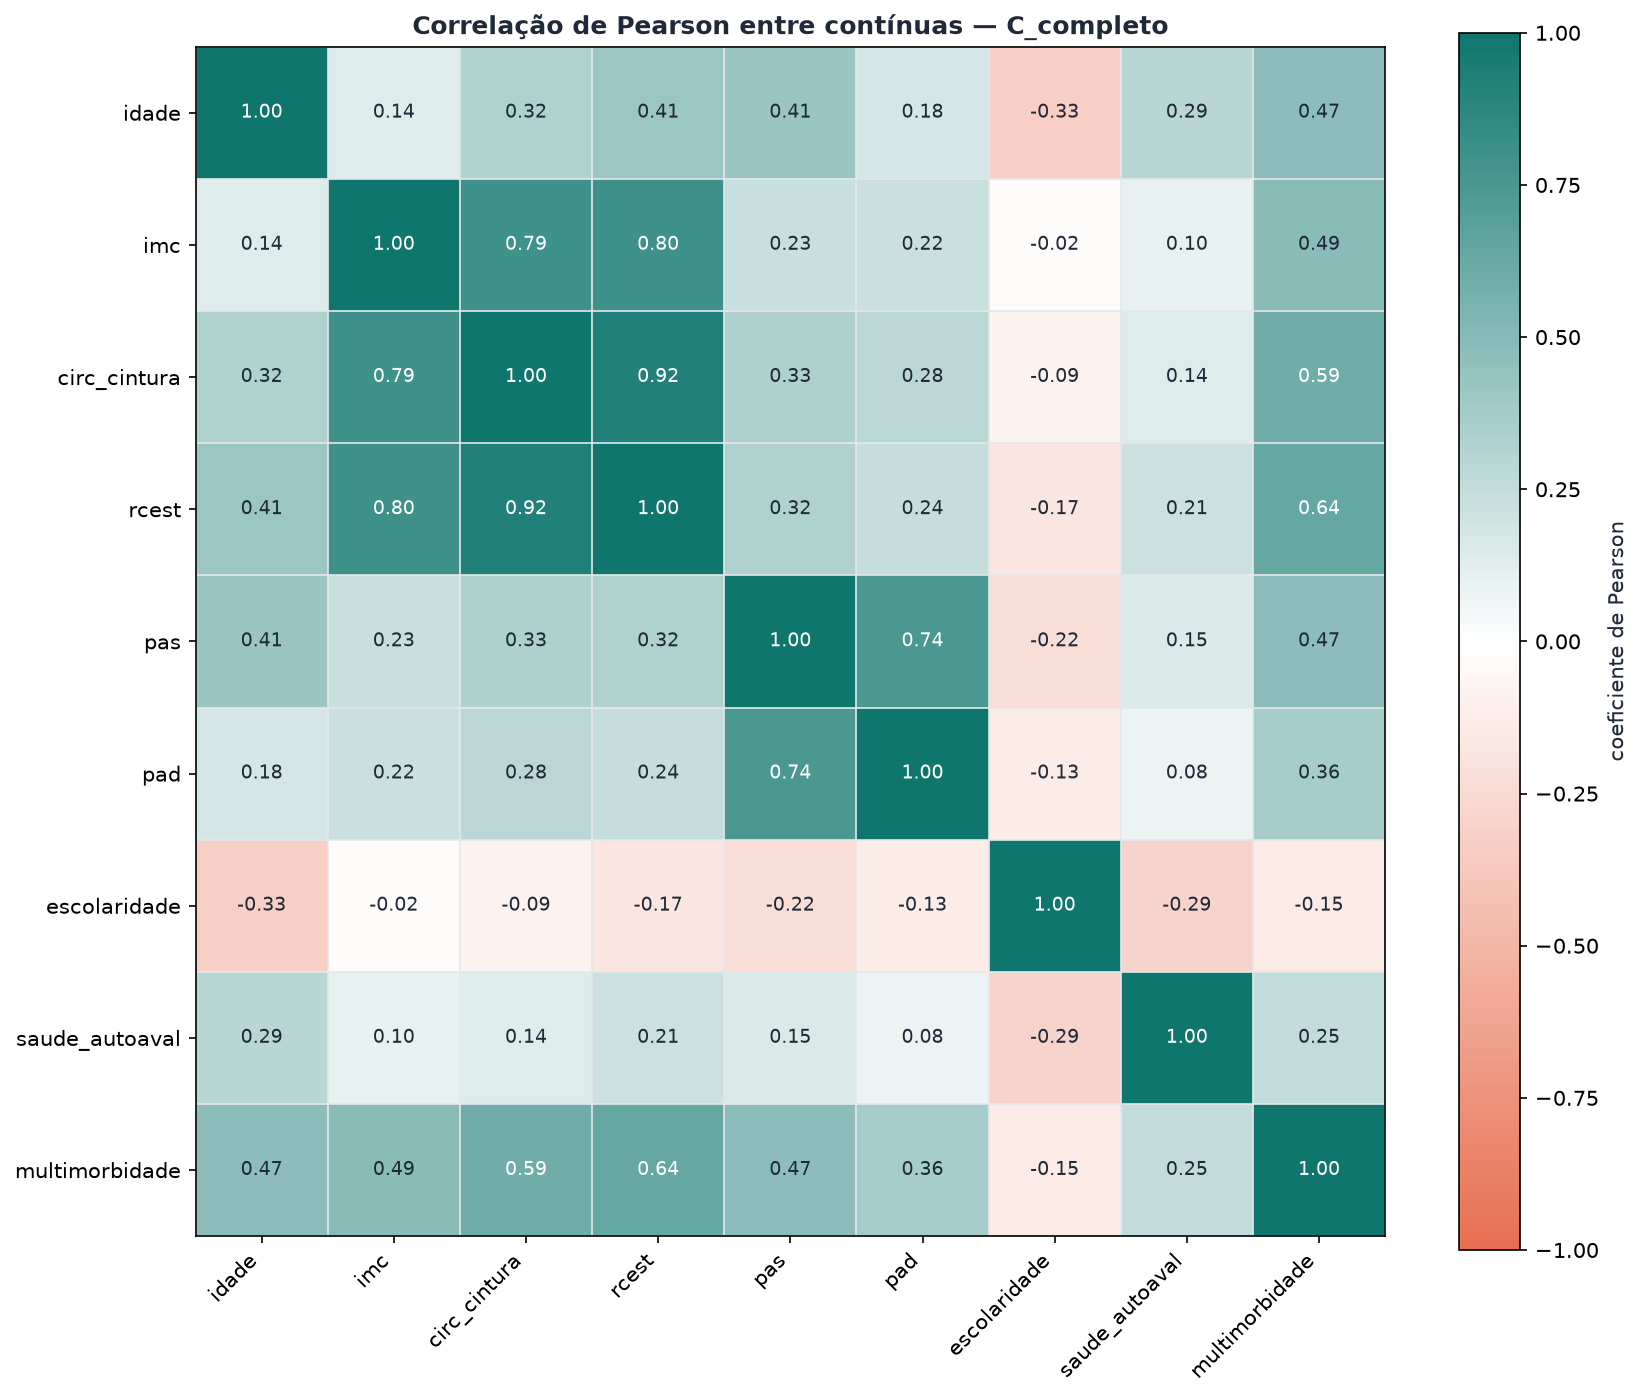

In [ ]:
display(Image(filename=str(diag["figuras"]["C_completo"])))

O par `rcest` × `circ_cintura` tem Pearson 0,92, o que é esperado: a razão cintura-estatura é construída a partir da cintura. É a colinearidade que o protocolo da §6.5 manda tratar por remoção experimental.

In [ ]:
pares = diag["pares_pearson"]
pares[pares["abs_pearson"] >= 0.5]

,feature_set,var_1,var_2,pearson,abs_pearson
0,A_atomico,imc,circ_cintura,0.792602,0.792602
1,A_atomico,pas,pad,0.742631,0.742631
21,B_composto,imc,circ_cintura,0.792602,0.792602
22,B_composto,circ_cintura,multimorbidade,0.587511,0.587511
36,C_completo,circ_cintura,rcest,0.916153,0.916153
37,C_completo,imc,rcest,0.799232,0.799232
38,C_completo,imc,circ_cintura,0.792602,0.792602
39,C_completo,pas,pad,0.742631,0.742631
40,C_completo,rcest,multimorbidade,0.636275,0.636275
41,C_completo,circ_cintura,multimorbidade,0.587511,0.587511


## 3. Escolha do conjunto de atributos

Duas decisões se resolvem aqui, e **nenhuma das duas por desempenho**: ambas pela estrutura das variáveis.

**Primeira: `rcest` sai.** VIF 14,03 no conjunto completo; removida, `circ_cintura` cai de 13,73 para 4,70. Execução do protocolo da §6.5, não escolha ad hoc.

In [ ]:
diag["ablacao_rcest"]

,variavel,vif_antes,r2_antes,acima_antes,vif_depois,r2_depois,acima_depois,delta_vif
0,circ_cintura,13.732556,0.927180,True,4.703812,0.787406,False,-9.028744
1,multimorbidade,8.604231,0.883778,False,8.604055,0.883776,False,-0.000176
2,has_combinada,6.028235,0.834114,False,6.027964,0.834107,False,-0.000271
3,imc,3.388618,0.704894,False,3.124849,0.679985,False,-0.263769
4,pas,3.040225,0.671077,False,3.039542,0.671003,False,-0.000684
5,has_autorrelato_3.0,2.848924,0.648990,False,2.848903,0.648988,False,-0.000021
6,colesterol_sim,2.520791,0.603299,False,2.520509,0.603255,False,-0.000282
7,pad,2.507037,0.601123,False,2.505722,0.600913,False,-0.001314
8,sexo_fem,2.277650,0.560951,False,1.581508,0.367692,False,-0.696142
9,idade,1.974118,0.493445,False,1.790797,0.441590,False,-0.183321


**Segunda: `C_completo` é descartado.** O escore de multimorbidade é, por construção, a soma de três parcelas binárias que também são colunas do modelo. Reconstruí-lo a partir delas dá R² = 1,000: identidade algébrica, não estimativa. A regressão auxiliar do VIF, que só enxerga `imc` e `circ_cintura` contínuas, chega a 0,884.

A distância entre os dois é a parcela da redundância que o diagnóstico linear **não enxerga**: o ponto de corte que binariza a obesidade não é recuperável por combinação linear. O argumento que descarta C é o Princípio 4; a evidência é este par de R².

In [ ]:
decomposicao = diag["decomposicao_escore"]
print(f"R2 identidade (parcelas exatas): {decomposicao['r2_identidade']:.3f}")
print(f"R2 regressao auxiliar do VIF:    {decomposicao['r2_vif']:.3f}")
print(f"VIF de multimorbidade:           {decomposicao['vif']:.2f}")
print("Parcelas: " + ", ".join(decomposicao["parcelas"]))

R2 identidade (parcelas exatas): 1.000
R2 regressao auxiliar do VIF:    0.884
VIF de multimorbidade:           8.60
Parcelas: has_combinada, colesterol_sim, obesidade_reconstruida


Restam A e B. A decisão entre eles fica para depois da tabela de desempenho da seção seguinte, onde se vê que **não é uma decisão de métrica**.

## 4. Desempenho da Regressão Logística

O grid roda aqui. O produto cartesiano não é cheio: a regra ADA e o Dummy não dependem do conjunto de atributos e são avaliados uma vez cada. A Random Forest está fora de `MODELOS_PADRAO`; os hiperparâmetros dela são placeholder declarado até a Sprint 2.

A chamada emite `comparativo_consolidado` e `carga_operacional` em `reports/tabelas/`, salva as figuras do teste e confere o resultado contra o artefato rastreado da Sprint 1.

In [ ]:
saida = exp.executar(particao=particao, salvar_figuras=True)

logreg = [r for r in saida["resultados"] if r["modelo"] == "LogReg"]
ev.comparar_formatado(logreg)

,modelo,conjunto,limiar,recall,especificidade,f1,auc_roc,nns
0,LogReg,A_atomico,0.424,0.748 (0.802 ± 0.027),0.627 (0.644 ± 0.015),0.224 (0.246 ± 0.010),0.775 (0.786 ± 0.015),7.58
1,LogReg,B_composto,0.445,0.765 (0.802 ± 0.008),0.637 (0.640 ± 0.023),0.233 (0.244 ± 0.011),0.781 (0.782 ± 0.013),7.26
2,LogReg,C_completo,0.419,0.756 (0.802 ± 0.026),0.625 (0.642 ± 0.015),0.226 (0.245 ± 0.007),0.770 (0.787 ± 0.014),7.54


Formato `teste (CV: média ± dp)`. A dispersão entre folds não é enfeite: é a escala que diz se a diferença entre conjuntos significa alguma coisa.

**E não significa.** A vantagem de B sobre A em recall é 0,017; o desvio entre folds do próprio A é 0,027. A diferença entre conjuntos é menor que a variação de partição dentro de um deles. A escolha de `B_composto` se decide por parcimônia e interpretabilidade (16 colunas contra 20), e é assim que ela deve ser apresentada à banca.

Modelo de referencia (menor NNS entre os calibraveis): LogReg / B_composto - NNS 7.26


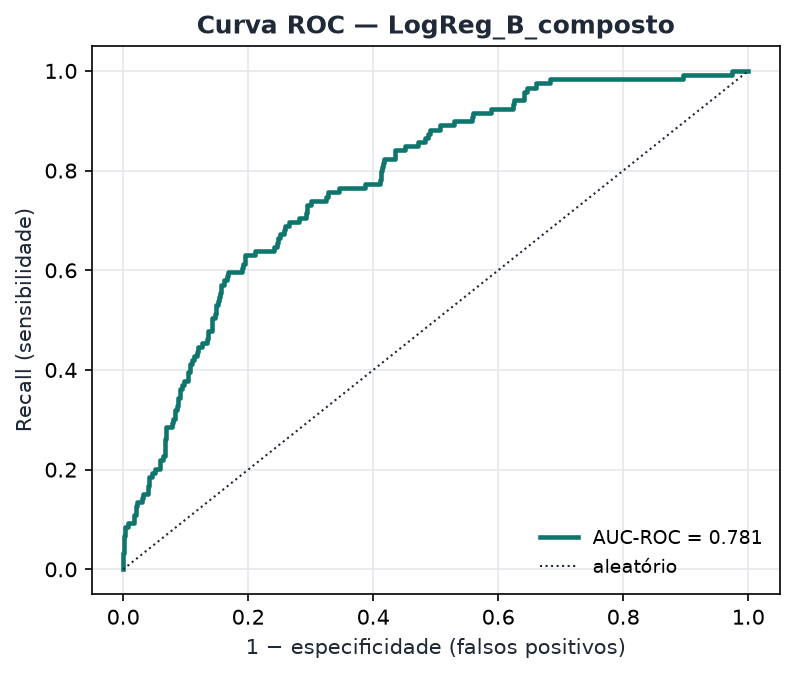

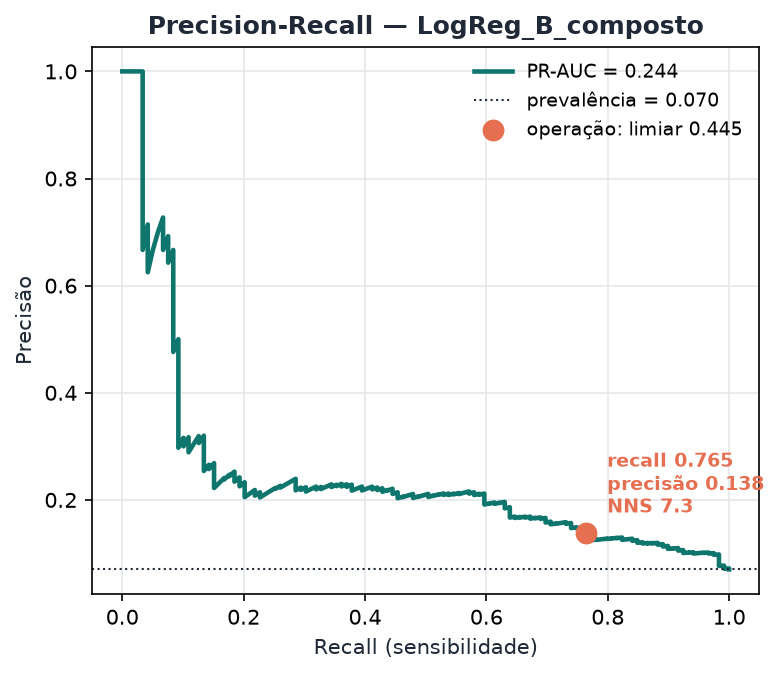

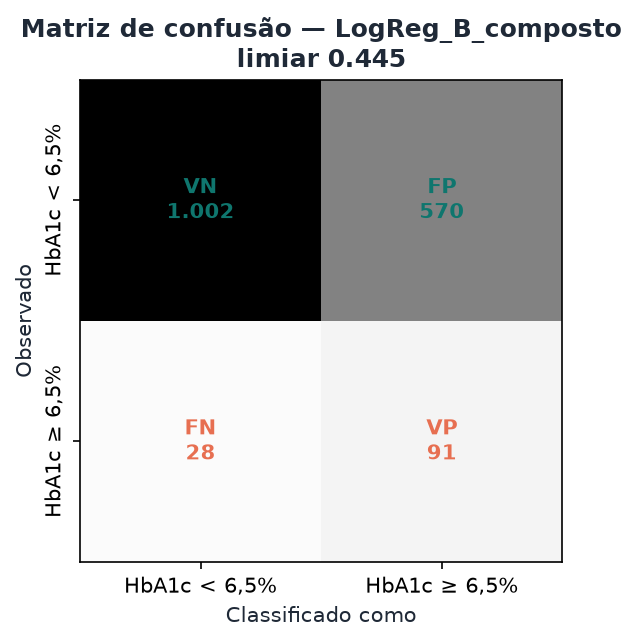

In [ ]:
referencia = exp.modelo_de_referencia(saida["resultados"])
print(f"Modelo de referencia (menor NNS entre os calibraveis): "
      f"{referencia['modelo']} / {referencia['conjunto']} - NNS {referencia['nns']:.2f}")

for chave in ("roc", "precision_recall", "confusao"):
    display(Image(filename=str(referencia["figuras"][chave])))

## 5. Calibração

**As probabilidades do modelo não são risco individual.** O intercepto de calibração reproduz o logito da prevalência de treino, deslocamento algébrico previsível do `class_weight='balanced'`: o reequilíbrio de classes desloca a escala inteira para cima.

O slope entre 0,84 e 0,92 diz que a **ordenação** é válida, e ordenação é tudo que a triagem precisa, porque a decisão é o limiar. A escala não é. Um escore de 0,60 corresponde a frequência observada de cerca de 7%. Essa é uma limitação a declarar nos resultados, não um defeito a esconder.

In [ ]:
ev.tabela_calibracao_comparada(logreg)

,modelo,conjunto,brier,brier_trivial,brier_skill,prevalencia,proba_media,razao_inflacao,ece,slope,intercepto
0,LogReg,A_atomico,0.192154,0.06542,-1.937225,0.070373,0.393509,5.591797,0.323137,0.872940,-2.570574
1,LogReg,B_composto,0.195942,0.06542,-1.995125,0.070373,0.398668,5.665111,0.328296,0.919974,-2.588583
2,LogReg,C_completo,0.192693,0.06542,-1.945467,0.070373,0.392640,5.579450,0.322268,0.835894,-2.560894


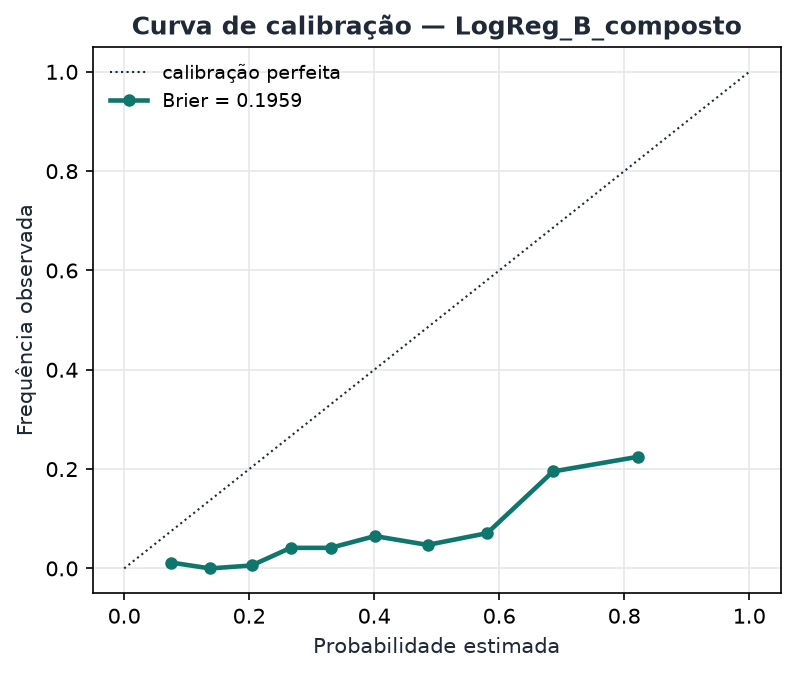

In [ ]:
display(Image(filename=str(referencia["figuras"]["calibracao"])))

## 6. Comparadores não-ML

Dois pisos. A **regra clínica ADA** (`idade ≥ 45 OU IMC ≥ 30`) é o comparador que importa: é o que a rede já faz hoje. O **Dummy** existe para tornar visível o que a prevalência de 7% permite, acertar 93% das vezes sem classificar ninguém.

In [ ]:
ev.comparar_formatado(saida["resultados"])

,modelo,conjunto,limiar,recall,especificidade,f1,auc_roc,nns
0,LogReg,A_atomico,0.424,0.748 (0.802 ± 0.027),0.627 (0.644 ± 0.015),0.224 (0.246 ± 0.010),0.775 (0.786 ± 0.015),7.58
1,LogReg,B_composto,0.445,0.765 (0.802 ± 0.008),0.637 (0.640 ± 0.023),0.233 (0.244 ± 0.011),0.781 (0.782 ± 0.013),7.26
2,LogReg,C_completo,0.419,0.756 (0.802 ± 0.026),0.625 (0.642 ± 0.015),0.226 (0.245 ± 0.007),0.770 (0.787 ± 0.014),7.54
3,Regra ADA,—,0.500,0.866 (0.894 ± 0.025),0.446 (0.454 ± 0.017),0.188 (0.196 ± 0.008),0.656 (0.674 ± 0.018),9.46
4,Dummy (maioria),—,0.500,0.000 (0.000 ± 0.000),1.000 (1.000 ± 0.000),0.000 (0.000 ± 0.000),0.500 (0.500 ± 0.000),inf


In [ ]:
print(ev.nota_corte_unico(saida["consolidado"]))

Nota: Dummy (maioria), Regra ADA são classificadores de corte único — a saída assume dois valores, não um escore. AUC-ROC, PR-AUC, Brier e a curva de calibração dependem de percorrer limiares e, para essas linhas, ficam degradadas por construção, não por desempenho. As métricas comparáveis entre todas as linhas são Recall, Especificidade e NNS.


Aplicado o critério de sucesso da §7 (mais recall **com** NNS menor, conjuntivamente), nenhum modelo domina a regra. Isso diz mais sobre os pontos de operação do que sobre os classificadores: o modelo está calibrado em recall-alvo 0,80 e a regra opera em 0,87. Comparação entre estratégias em recalls diferentes não é comparação. É o que a próxima seção resolve.

In [ ]:
bm.supera_a_regra_clinica(saida["resultados"])

,estrategia,recall_alvo,recall_obtido,recall_regra,delta_recall,nns,nns_regra,delta_nns,supera
0,LogReg · A_atomico,0.8,0.747899,0.865546,-0.117647,7.584270,9.456311,-1.872041,False
1,LogReg · B_composto,0.8,0.764706,0.865546,-0.100840,7.263736,9.456311,-2.192574,False
2,LogReg · C_completo,0.8,0.756303,0.865546,-0.109244,7.544444,9.456311,-1.911866,False
3,Dummy (maioria),NaN,0.000000,0.865546,-0.865546,inf,9.456311,inf,False


## 7. Carga operacional

Os três regimes de encaminhamento. É o resultado que sustenta a conclusão do trabalho.

O regime equiparado recalibra o modelo de referência no recall que a regra obtém **no treino**. Medi-lo no teste vazaria o teste para dentro da decisão de limiar (R1/R2). É o cálculo mais frágil da Sprint 1, o único que atravessa treino e teste de propósito, e por isso o que mais precisava estar versionado.

In [ ]:
saida["carga"]

,regime,encaminhados,taxa_encaminhamento,casos_detectados,casos_perdidos,recall,nns
0,Regra ADA,974,0.575991,103,16,0.865546,9.456311
1,"LogReg · B_composto, recall equiparado (alvo 0...",1000,0.591366,109,10,0.915966,9.174312
2,"LogReg · B_composto, ponto padrão (recall-alvo...",661,0.390893,91,28,0.764706,7.263736


In [ ]:
print(saida["carga"].attrs["leitura"])

Regra ADA encaminha 974 de 1691 pessoas (57.6%) para detectar 103 casos. LogReg · B_composto encaminha 661 (39.1%) para detectar 91. Uma triagem que encaminha mais da metade da população adulta não seleciona quem examinar — apenas desloca a fila para o laboratório. No regime de recall equiparado, LogReg · B_composto encaminha 26 pessoas a mais (1000 contra 974) e detecta 6 casos a mais (109 contra 103), mantendo NNS inferior (9.17 contra 9.46): a comparação válida é por NNS, não por volume absoluto, já que os recalls realizados diferem (0.916 contra 0.866).


**Cuidado de leitura.** No regime equiparado o modelo encaminha *mais* gente que a regra em números absolutos: 1.000 contra 974. Lida isoladamente, a tabela sugere desvantagem. A resposta está no recall realizado, 0,916 contra 0,866, e é o que o NNS já incorpora por normalizar pelos casos detectados. Volume absoluto só é comparável entre estratégias que operam no mesmo recall.

A advertência acompanha a tabela em `attrs["nota"]`, para que ela não circule sem.

In [ ]:
print(saida["carga"].attrs["nota"])

Volume de encaminhamentos só é comparável entre estratégias que operam no mesmo recall. Quando os recalls realizados diferem, a comparação é por NNS, que normaliza por casos detectados — no regime de recall equiparado um modelo pode encaminhar mais pessoas que a regra em números absolutos e ainda assim ter NNS menor, por detectar mais casos.


A vantagem do modelo não é fazer o mesmo um pouco melhor: é **poder escolher o ponto de operação** conforme a capacidade instalada da rede, o que uma regra de corte único por definição não permite. A troca é explícita e quantificada: 313 encaminhamentos a menos ao custo de 12 casos não detectados, ou o inverso.

## 8. Conferência de reprodução e artefatos

Os resultados da Sprint 1 não eram reproduzíveis por código versionado: das cinco linhas da tabela consolidada, só as três da LogReg tinham artefato rastreado em git. É essa lacuna que `src/experimento.py` fecha.

A conferência abaixo usa `comparativo_logreg.tex` como âncora (o único artefato disponível) e exige coincidência até a terceira casa. Tabela vazia significa reprodução exata no escopo coberto. As demais linhas foram estabelecidas por esta execução e passam a ser a referência.

In [ ]:
saida["divergencias"]

,linha,coluna,referencia,obtido


In [ ]:
for nome, caminhos in saida["artefatos"].items():
    print(f"{nome}: {caminhos['tex'].name} / {caminhos['csv'].name}")

comparativo_consolidado: comparativo_consolidado.tex / comparativo_consolidado.csv
carga_operacional: carga_operacional.tex / carga_operacional.csv


**Próxima sprint.** Random Forest, com busca de hiperparâmetros. O grid já a aceita via `python -m src.experimento --modelos LogReg "Random Forest"`. Em seguida, SHAP: `LinearExplainer` para a logística, `TreeExplainer` para a floresta.